In [1]:
# Data Wrangling
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('white')


import scipy
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Dense, Input
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

# Text Preprocessing
import string
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer

# model training and tuning
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV, RandomizedSearchCV
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score

#LSTM Modelling
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense, Dropout, SpatialDropout1D
from tensorflow.keras.layers import Embedding

# ignore the warnings from sklearn
import warnings
warnings.filterwarnings('ignore')

In [2]:
from keras.layers import Dense,Dropout,Embedding,LSTM,Conv1D,GlobalMaxPooling1D,Flatten,MaxPooling1D,GRU,SpatialDropout1D,Bidirectional

In [3]:
#LSTM Modelling

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM,Dense, Dropout, SpatialDropout1D
from tensorflow.keras.layers import Embedding

In [4]:
# importing the data

df = pd.read_csv('kindle_reviews.csv')

## Exploratory Data Analysis

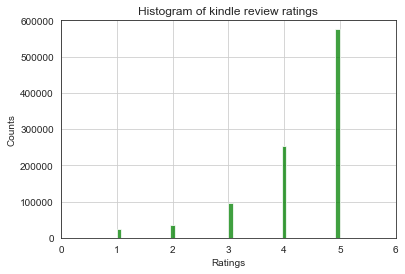

In [5]:
# the histogram of the ratings
plt.hist(df['overall'], 50, facecolor='green', alpha=0.75)
plt.xlabel('Ratings')
plt.ylabel('Counts')
plt.title('Histogram of kindle review ratings')
plt.axis([0, 6,0,600000])
plt.grid(True)

In [6]:
# dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 982619 entries, 0 to 982618
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   Unnamed: 0      982619 non-null  int64 
 1   asin            982619 non-null  object
 2   helpful         982619 non-null  object
 3   overall         982619 non-null  int64 
 4   reviewText      982597 non-null  object
 5   reviewTime      982619 non-null  object
 6   reviewerID      982619 non-null  object
 7   reviewerName    978803 non-null  object
 8   summary         982618 non-null  object
 9   unixReviewTime  982619 non-null  int64 
dtypes: int64(3), object(7)
memory usage: 75.0+ MB


In [7]:
# checking missing values
df.isnull().sum()

Unnamed: 0           0
asin                 0
helpful              0
overall              0
reviewText          22
reviewTime           0
reviewerID           0
reviewerName      3816
summary              1
unixReviewTime       0
dtype: int64

In [8]:
#contained an extra Unnamed column
df.drop(df.columns[0], axis = 1, inplace = True)

#drop the rows where there are no reviews
df.dropna(subset = ['reviewText'], inplace = True)

#changing the reviewTime column to be of datetime type
df.reviewTime = pd.to_datetime(df.reviewTime)

#creating a column with just the year
df['Year'] = df.reviewTime.dt.year
df.head()

,asin,helpful,overall,reviewText,reviewTime,reviewerID,reviewerName,summary,unixReviewTime,Year
0,B000F83SZQ,"[0, 0]",5,I enjoy vintage books and movies so I enjoyed ...,2014-05-05,A1F6404F1VG29J,Avidreader,Nice vintage story,1399248000,2014
1,B000F83SZQ,"[2, 2]",4,This book is a reissue of an old one; the auth...,2014-01-06,AN0N05A9LIJEQ,critters,Different...,1388966400,2014
2,B000F83SZQ,"[2, 2]",4,This was a fairly interesting read. It had ol...,2014-04-04,A795DMNCJILA6,dot,Oldie,1396569600,2014
3,B000F83SZQ,"[1, 1]",5,I'd never read any of the Amy Brewster mysteri...,2014-02-19,A1FV0SX13TWVXQ,"Elaine H. Turley ""Montana Songbird""",I really liked it.,1392768000,2014
4,B000F83SZQ,"[0, 1]",4,"If you like period pieces - clothing, lingo, y...",2014-03-19,A3SPTOKDG7WBLN,Father Dowling Fan,Period Mystery,1395187200,2014


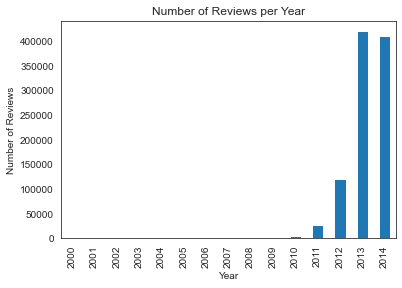

In [9]:
# Analyzing number of reviews per year
df.Year.value_counts().sort_index().plot(kind = 'bar')
plt.title('Number of Reviews per Year')
plt.xlabel('Year')
plt.ylabel('Number of Reviews')
plt.show()

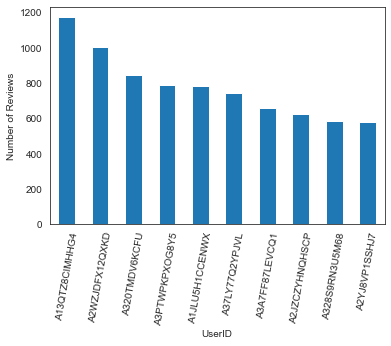

In [10]:
# checkinng top 10 users base on the number of reviews made
df.reviewerID.value_counts().head(10).plot(kind = 'bar')
plt.xticks(rotation = 80)
plt.xlabel('UserID')
plt.ylabel('Number of Reviews')
plt.show()

In [11]:
# checking the overall average review on all the ratings.
df.overall.mean()

4.347791617519695

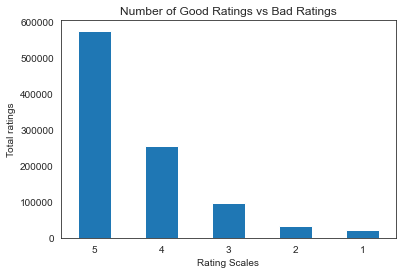

In [12]:
# checking how many ratings i have per scale.
df.overall.value_counts().plot(kind = 'bar')
plt.title('Number of Good Ratings vs Bad Ratings')
plt.xlabel('Rating Scales')
plt.xticks(rotation = 0)
plt.ylabel('Total ratings')
plt.show()

## TEXT PRE-PROCESSING

In [13]:
#created a dataframe that only contains the reviewText and the overall scoring of item
reviews = df[['reviewText', 'overall']]
reviews.head()

,reviewText,overall
0,I enjoy vintage books and movies so I enjoyed ...,5
1,This book is a reissue of an old one; the auth...,4
2,This was a fairly interesting read. It had ol...,4
3,I'd never read any of the Amy Brewster mysteri...,5
4,"If you like period pieces - clothing, lingo, y...",4


In [14]:
# printing the original text
print('Original Text: ' + str(reviews['reviewText'][1]))
print('\n')

Original Text: This book is a reissue of an old one; the author was born in 1910. It's of the era of, say, Nero Wolfe. The introduction was quite interesting, explaining who the author was and why he's been forgotten; I'd never heard of him.The language is a little dated at times, like calling a gun a &#34;heater.&#34;  I also made good use of my Fire's dictionary to look up words like &#34;deshabille&#34; and &#34;Canarsie.&#34; Still, it was well worth a look-see.




In [15]:
# create an empty mapping table from the str object to strip punctuation from the words
punc = str.maketrans('', '', string.punctuation)
# apply the empty mapping table to each element of the series where x is the review for one document.
reviews['reviewText'] = reviews['reviewText'].apply(lambda x : ' '.join(word.translate(punc) for word in x.split()))
print('Punctuation Remove: ' + str(reviews['reviewText'][1]))
print('\n')

Punctuation Remove: This book is a reissue of an old one the author was born in 1910 Its of the era of say Nero Wolfe The introduction was quite interesting explaining who the author was and why hes been forgotten Id never heard of himThe language is a little dated at times like calling a gun a 34heater34 I also made good use of my Fires dictionary to look up words like 34deshabille34 and 34Canarsie34 Still it was well worth a looksee




In [16]:
# removing words that is non alphabetical
reviews['reviewText'] = reviews['reviewText'].apply(lambda x: ' '.join(word for word in x.split() if word.isalpha()))
print('Alphabetical Words: '+ str(reviews['reviewText'][1]))
print('\n')

Alphabetical Words: This book is a reissue of an old one the author was born in Its of the era of say Nero Wolfe The introduction was quite interesting explaining who the author was and why hes been forgotten Id never heard of himThe language is a little dated at times like calling a gun a I also made good use of my Fires dictionary to look up words like and Still it was well worth a looksee




In [17]:
# making all words to be lowercase
reviews['reviewText'] = reviews['reviewText'].apply(lambda x: ' '.join(word.lower() for word in x.split()))
print('Lowercase Words : '+ str(reviews['reviewText'][1]))
print('\n')

Lowercase Words : this book is a reissue of an old one the author was born in its of the era of say nero wolfe the introduction was quite interesting explaining who the author was and why hes been forgotten id never heard of himthe language is a little dated at times like calling a gun a i also made good use of my fires dictionary to look up words like and still it was well worth a looksee




In [18]:
# list of stop words
stop = stopwords.words('english')
# removing the stop words
reviews['reviewText'] = reviews['reviewText'].apply(lambda x : ' '.join(word for word in x.split() if word not in stop))
print('Stopwords Remove: ' + str(reviews['reviewText'][1]))
print('\n')

Stopwords Remove: book reissue old one author born era say nero wolfe introduction quite interesting explaining author hes forgotten id never heard himthe language little dated times like calling gun also made good use fires dictionary look words like still well worth looksee




In [19]:
# Lemmatize words to reduce them to their root form. Note: added the pos = 'v' to reduce the incoming word to verb root
lem = WordNetLemmatizer()
reviews['reviewText'] = reviews['reviewText'].apply(lambda x : ' '.join(lem.lemmatize(word, pos = 'v') for word in x.split()))
print('Lemmatized Text: ' + str(reviews['reviewText'][1]))

Lemmatized Text: book reissue old one author bear era say nero wolfe introduction quite interest explain author hes forget id never hear himthe language little date time like call gun also make good use fire dictionary look word like still well worth looksee


In [20]:
#separating the ratings to different sentiment 
r1 = reviews[reviews.overall.isin([4,5,3])]
r0 = reviews[reviews.overall.isin([1,2])]
r2 = reviews[reviews.overall.isin([3])]

r1.loc[:, 'overall'] = 1
r0.loc[:, 'overall'] = 0

#concat the two new dataframes return one dataframe with preprocessed text and their corresponding labels
rev = pd.concat([r1,r0])
rev.head()

,reviewText,overall
0,enjoy vintage book movies enjoy read book plot...,1
1,book reissue old one author bear era say nero ...,1
2,fairly interest read old style terminologyi gl...,1
3,id never read amy brewster mysteries one reall...,1
4,like period piece clothe lingo enjoy mystery a...,1


# MACHINE LEARNING

## 1. MULTINOMIAL NAIVE BAYES

In [21]:
#checking overall values count where 1 = good rating while 0 = bad ratings
rev.overall.value_counts()

1    925449
0     57148
Name: overall, dtype: int64

In [22]:
#balancing the training data by downsampling to the minority class given there is a good amount of data
def make_xy(data, vec, n):
    """Takes in a dataframe with text and labels and returns a vocabulary of some sort
        depending on the vectorizer used.
        
        Arguments:
        
        data - the input dataframe containing the text and the labels
        
        vec - the chosen vectorizer to use
        
        n - the number of samples per class
        """
    temp = pd.DataFrame()
    #sampling only n class reviews per class
    for rating in range(2):
        temp = pd.concat([temp, data[data.overall == rating].sample(n, random_state = 42)], ignore_index = True)
    #vectorizing the vocabulary
    X = vec.fit_transform(temp.reviewText)
    y = temp.overall
    return X, y

In [23]:
#using CountVectorizer
count = CountVectorizer()
X, y = make_xy(rev, count, 20000)

In [24]:
#using TfidfVectorizer
tfidf = TfidfVectorizer()
Xt, yt = make_xy(rev, tfidf, 20000)

In [25]:
#testing the model with CountVectorizer
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .3, random_state = 42, stratify = y)

naive = MultinomialNB()
naive.fit(X_train, y_train)
print('Training Accuracy w/ CountVectorizer: {:.2f}'.format(naive.score(X_train, y_train)))
print('Testing Accuracy w/ CountVectorizer: {:.2f}'.format(naive.score(X_test, y_test)))

Training Accuracy w/ CountVectorizer: 0.91
Testing Accuracy w/ CountVectorizer: 0.87


In [26]:
#testing the model with tfidf vectorizer
Xt_train, Xt_test, yt_train, yt_test = train_test_split(Xt, yt, test_size = .3, random_state = 42, stratify = y)

nb = MultinomialNB()
nb.fit(Xt_train, yt_train)
print('Training Accuracy w/ TfidfVectorizer: {:.2f}'.format(nb.score(Xt_train, yt_train)))
print('Testing Accuracy w/ TfidfVectorizer: {:.2f}'.format(nb.score(Xt_test, yt_test)))

Training Accuracy w/ TfidfVectorizer: 0.91
Testing Accuracy w/ TfidfVectorizer: 0.87


In [27]:
X.shape

(40000, 84510)

### HYPERPARAMETER TUNING ON NAIVE BAYES

In [76]:
#Tuning the min_df parameter for the vectorizer and the alpha in the multinomial Naive Bayes
best_alpha = 0
best_min_df = 0
best_score = 0

#param_grid
alphas = [.1, 1, 5, 10, 50]
min_dfs = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]

#iterate throughout the param grid
for alpha in alphas:
    for m_df in min_dfs:
        tfidf = TfidfVectorizer(min_df = m_df)
        X, y = make_xy(rev, tfidf, 20000)
        naive = MultinomialNB(alpha = alpha)
        score = np.mean(cross_val_score(naive, X, y, scoring = 'accuracy', cv = 3))
        if score > best_score:
            best_score = score
            best_alpha = alpha
            best_min_df = m_df

In [77]:
print('Best_score: {:.2f}'.format(best_score))
print('Best_alpha: {:.2f}'.format(best_alpha))
print('Best_min_df: {:.5f}'.format(best_min_df))

Best_score: 0.87
Best_alpha: 5.00
Best_min_df: 0.00001


In [78]:
tfidf = TfidfVectorizer(min_df = .001)
X, y = make_xy(rev,tfidf, 20000)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .3, random_state = 42, stratify = y)
naive = MultinomialNB(alpha = 5)
naive.fit(X_train, y_train)
naive_pred = naive.predict(X_test)
naive_prob = naive.predict_proba(X_test)[:,1]


print('Training Accuracy w/ TfidfVectorizer: {:.2f}'.format(naive.score(X_train, y_train)))
print('Testing Accuracy w/ TfidfVectorizer: {:.2f}'.format(naive.score(X_test, y_test)))
print('\n')
print(confusion_matrix(y_test, naive_pred))
print('\n')
print(classification_report(y_test, naive_pred))

Training Accuracy w/ TfidfVectorizer: 0.88
Testing Accuracy w/ TfidfVectorizer: 0.87


[[5333  667]
 [ 887 5113]]


              precision    recall  f1-score   support

           0       0.86      0.89      0.87      6000
           1       0.88      0.85      0.87      6000

    accuracy                           0.87     12000
   macro avg       0.87      0.87      0.87     12000
weighted avg       0.87      0.87      0.87     12000



In [79]:
X_train.shape

(28000, 3690)

## 2. LOGISTIC REGRESSION

In [80]:
#creating a grid space
c_space = np.logspace(-5,6, 15)
penalty = ['l1', 'l2']
param_grid = {'C':c_space, 'penalty': penalty}
logreg = LogisticRegression()

#exhaustive search for the best parameters
logreg_cv = GridSearchCV(logreg, param_grid, cv = 5)
logreg_cv.fit(X_train,y_train)

#train model using the best parameters determine from GridSearchCV
logreg = LogisticRegression(C = logreg_cv.best_params_['C'], penalty = logreg_cv.best_params_['penalty'])
logreg.fit(X_train, y_train)
logreg_pred = logreg.predict(X_test)
logreg_prob = logreg.predict_proba(X_test)[:,1]

print('Training Accuracy w/ TfidfVectorizer: {:.2f}'.format(logreg.score(X_train, y_train)))
print('Testing Accuracy w/ TfidfVectorizer: {:.2f}'.format(logreg.score(X_test, y_test)))
print('\n')
print(confusion_matrix(y_test, logreg_pred))
print('\n')
print(classification_report(y_test, logreg_pred))

Training Accuracy w/ TfidfVectorizer: 0.89
Testing Accuracy w/ TfidfVectorizer: 0.88


[[5339  661]
 [ 801 5199]]


              precision    recall  f1-score   support

           0       0.87      0.89      0.88      6000
           1       0.89      0.87      0.88      6000

    accuracy                           0.88     12000
   macro avg       0.88      0.88      0.88     12000
weighted avg       0.88      0.88      0.88     12000



## 3. SUPPORT VECTOR CLASSIFIER

In [81]:
#creating array of regularization values
c_space = np.logspace(-5,6, 8)
best_score = []
score = 0
best_c = 0

#exhaustive search for the best parameters
for value in c_space:
    svm = LinearSVC(C = value)
    score = np.mean(cross_val_score(naive, X_train, y_train, scoring = 'accuracy', cv = 5))
    if score > best_score:
        best_score = score
        best_c = value

#train model using the best parameters determine from kfold
try:
    svm = LinearSVC(best_c)
    svm.fit(X_train, y_train)
    svm_pred = svm.predict(X_test)
    
except:
    svm = LinearSVC()
    svm.fit(X_train, y_train)
    svm_pred = svm.predict(X_test)

print('Training Accuracy w/ TfidfVectorizer: {:.2f}'.format(svm.score(X_train, y_train)))
print('Testing Accuracy w/ TfidfVectorizer: {:.2f}'.format(svm.score(X_test, y_test)))
print('\n')
print(confusion_matrix(y_test, svm_pred))
print('\n')
print(classification_report(y_test, svm_pred))

Training Accuracy w/ TfidfVectorizer: 0.91
Testing Accuracy w/ TfidfVectorizer: 0.87


[[5242  758]
 [ 815 5185]]


              precision    recall  f1-score   support

           0       0.87      0.87      0.87      6000
           1       0.87      0.86      0.87      6000

    accuracy                           0.87     12000
   macro avg       0.87      0.87      0.87     12000
weighted avg       0.87      0.87      0.87     12000



## 4. RANDOM FOREST CLASSIFIER

In [82]:
#Random Forest Classifier
rf = RandomForestClassifier()
#param_grid
rf_params = {'n_estimators':[100, 500, 1000, 1500, 2000], 
             'max_depth': [5, 10, 20, 30 ,40], 
             'max_features': ['sqrt', 'log2'],
            'min_samples_leaf': [10, 100, 500, 1000, 2000],
            'min_samples_split': [200, 500, 1000, 2000]}

#fitting the randomize search
rf_cv = RandomizedSearchCV(rf, rf_params, cv = 3, n_jobs = -1)
rf_cv.fit(X_train,y_train)

RandomizedSearchCV(cv=3, estimator=RandomForestClassifier(), n_jobs=-1,
                   param_distributions={'max_depth': [5, 10, 20, 30, 40],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_leaf': [10, 100, 500, 1000,
                                                             2000],
                                        'min_samples_split': [200, 500, 1000,
                                                              2000],
                                        'n_estimators': [100, 500, 1000, 1500,
                                                         2000]})

In [83]:
best_model = rf_cv.best_estimator_
best_model.fit(X_train, y_train)
rf_pred = best_model.predict(X_test)
rf_prob = best_model.predict_proba(X_test)[:,1]
print(rf_cv.best_params_)
print('Training Accuracy w/ TfidfVectorizer: {:.2f}'.format(best_model.score(X_train, y_train)))
print('Testing Accuracy w/ TfidfVectorizer: {:.2f}'.format(best_model.score(X_test, y_test)))
print('\n')
print(confusion_matrix(y_test, rf_pred))
print('\n')
print(classification_report(y_test, rf_pred))

{'n_estimators': 500, 'min_samples_split': 200, 'min_samples_leaf': 10, 'max_features': 'log2', 'max_depth': 40}
Training Accuracy w/ TfidfVectorizer: 0.88
Testing Accuracy w/ TfidfVectorizer: 0.86


[[5309  691]
 [ 964 5036]]


              precision    recall  f1-score   support

           0       0.85      0.88      0.87      6000
           1       0.88      0.84      0.86      6000

    accuracy                           0.86     12000
   macro avg       0.86      0.86      0.86     12000
weighted avg       0.86      0.86      0.86     12000



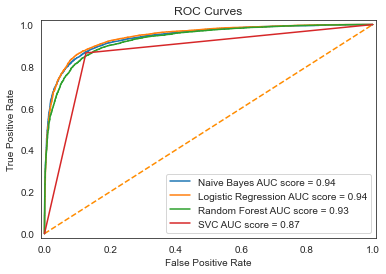

In [84]:
#Plotting the roc curves for each model
sns.set_style('white')
fig, ax = plt.subplots()
ax.plot([0,1], [0,1], linestyle = '--', color = 'darkorange')

probs = [naive_prob, logreg_prob, rf_prob, svm_pred]
labels = ['Naive Bayes', 'Logistic Regression', 'Random Forest', 'SVC']
for idx in range(len(probs)):
    fpr, tpr, thresholds = roc_curve(y_test, probs[idx])
    ax.plot(fpr, tpr, label = (labels[idx] + ' AUC score = %.2f' % roc_auc_score(y_test, probs[idx])))
    
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves')
ax.legend(loc = 'lower right')
ax.margins(x = 0.01, y =0.02)


plt.show()

# NEURAL NETWORK

## LSTM

In [37]:
my_data = rev

In [38]:
sentiment_label = my_data.overall.factorize()
sentiment_label

(array([0, 0, 0, ..., 1, 1, 1], dtype=int64),
 Int64Index([1, 0], dtype='int64'))

In [39]:
my_data.overall.value_counts()

1    925449
0     57148
Name: overall, dtype: int64

In [40]:
tweet = my_data.reviewText
tokenizer = Tokenizer(num_words=10000)
tokenizer.fit_on_texts(tweet)
vocab_size = len(tokenizer.word_index) + 1
encoded_docs = tokenizer.texts_to_sequences(tweet)
padded_sequence = pad_sequences(encoded_docs, maxlen=200)

In [41]:
embedding_vector_length = 32
model = Sequential() 
model.add(Embedding(vocab_size, embedding_vector_length, input_length=200) )
model.add(SpatialDropout1D(0.25))
model.add(LSTM(50, dropout=0.5, recurrent_dropout=0.5))
model.add(Dropout(0.2))
model.add(Dense(1, activation='sigmoid')) 
model.compile(loss='binary_crossentropy',optimizer='adam', metrics=['accuracy'])  
print(model.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 200, 32)           27066272  
                                                                 
 spatial_dropout1d (SpatialD  (None, 200, 32)          0         
 ropout1D)                                                       
                                                                 
 lstm (LSTM)                 (None, 50)                16600     
                                                                 
 dropout (Dropout)           (None, 50)                0         
                                                                 
 dense (Dense)               (None, 1)                 51        
                                                                 
Total params: 27,082,923
Trainable params: 27,082,923
Non-trainable params: 0
____________________________________________

In [42]:
history = model.fit(padded_sequence,sentiment_label[0],validation_split=0.25,epochs=3,batch_size=64)

Epoch 1/3
11515/11515 [==============================] - 7600s 658ms/step - loss: 9.8582e-04 - accuracy: 0.9999 - val_loss: 4.0198 - val_accuracy: 0.7674
Epoch 2/3
11515/11515 [==============================] - 17904s 2s/step - loss: 1.6266e-08 - accuracy: 1.0000 - val_loss: 5.2556 - val_accuracy: 0.7674
Epoch 3/3
11515/11515 [==============================] - 87565s 8s/step - loss: 3.8107e-10 - accuracy: 1.0000 - val_loss: 5.6534 - val_accuracy: 0.7674


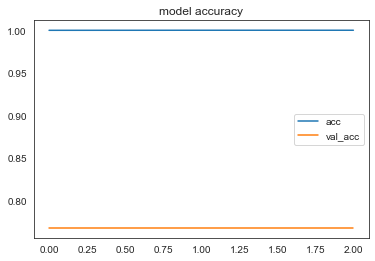

In [43]:
#model accuracy

plt.plot(history.history['accuracy'], label='acc')
plt.plot(history.history['val_accuracy'], label='val_acc')
plt.title('model accuracy')
plt.legend()
plt.show()

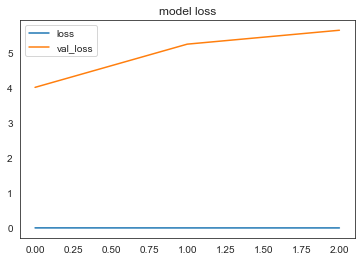

In [44]:
#model loss

plt.plot(history.history['loss'], label='loss')
plt.plot(history.history['val_loss'], label='val_loss')
plt.title('model loss')
plt.legend()
plt.show()